# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.

In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos. 

In [6]:
# revisar el número de filas y columnas de cada dataset
print("Dimensiones (filas, columnas):")
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

Dimensiones (filas, columnas):
plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
print("=== PLANS ===")
plans.info()

=== PLANS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
print("\n=== users ===")
users.info()


=== users ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
print("\n=== usage ===")
usage.info()


=== usage ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print("=== USERS: nulos por columna ===")
print(users.isna().sum())

print("=== USERS: proporción de nulos ===")
print(users.isna().mean()*100)

=== USERS: nulos por columna ===
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
=== USERS: proporción de nulos ===
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [11]:
print("\n=== USAGE: nulos por columna ===")
print (usage.isna().sum())

print("\n=== USAGE: proporción de nulos ===")
print (usage.isna().mean()*100)


=== USAGE: nulos por columna ===
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

=== USAGE: proporción de nulos ===
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?

  - `users`: `city` (11.7%, 469 filas) y `churn_date` (88.4%, 3,534 filas).
  - `usage`: `date` (0.1%, 50 filas), `duration` (55.2%) y `length` (44.7%).
- Indica qué harías: ¿imputar, eliminar, ignorar?

  -  `churn_date`: ignorar. Un nulo significa que el usuario sigue activo, así que es información válida.
  - `city`: investigar la causa y dejar como nulo (11.7% está en el rango de 5% a 30%).
  - `date`: dejar como nulo (0.1%). No se usa para contar mensajes y llamadas, y eliminar esas filas restaría actividad real a los usuarios.
  - `duration` y `length`: ignorar. Son nulos estructurales (una llamada tiene duración y un mensaje tiene longitud); se comprueba en 3.2.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000



- La columna `user_id` hay 4000 registros que empienzan en el numero de usuario 10000 y terminan en el 13999, sin anomalias aparentes.
- La columna `age` tiene un promedio de edad de 33.7 años con una desviacion estandar de 123, valores distorsionados por un sentinel: el valor -999, que aparece como edad mínima y no corresponde a una edad real. La edad máxima, de 79 años, es plausible. Se reemplazará -999 por un valor nulo y se recalcularán las estadísticas.


In [13]:
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- `id` y `user_id` no presentan anomalías. `id` es un índice consecutivo de 1 a 40000 y `user_id` está en el rango esperado (10000 a 13999), igual que en `users`, lo que permitirá combinar ambas tablas.
- `duration`: la media (5.2) es mayor que la mediana (3.5), lo que indica una distribución sesgada a la derecha. El máximo es exactamente 120 minutos, un valor tan redondo que puede ser un tope del sistema y conviene revisarlo. El mínimo de 0 puede corresponder a llamadas perdidas o no contestadas.
- `length`: la mediana es 50 y el percentil 75 es 64, pero el máximo es 1490, un valor sospechoso que podría ser un error de registro. Además, la desviación estándar (56.6) es mayor que la media (52.1), señal de que los extremos inflan la dispersión.



In [14]:
# explorar columnas categóricas de users

columnas_user = ['city', 'plan']


for col in columnas_user:
    print(f"=== {col.upper()} ===")
    print("Valores únicos:", users[col].nunique())
    print(users[col].value_counts(dropna=False))
    print()


=== CITY ===
Valores únicos: 7
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

=== PLAN ===
Valores únicos: 2
Basico     2595
Premium    1405
Name: plan, dtype: int64



In [15]:
# Investigar si la ausencia de city depende de otras variables (sin modificar users)
city_desconocida = users['city'].isna() | (users['city'] == '?')
edad_valida = users['age'] != -999

print("Ciudad desconocida por plan:")
print(pd.crosstab(users['plan'], city_desconocida, normalize='index').round(3))

print("\nCiudad desconocida según si el usuario se dio de baja:")
print(pd.crosstab(users['churn_date'].notna(), city_desconocida, normalize='index').round(3))

print("\nEdad mediana (sin -999) según ciudad desconocida:")
print(users.loc[edad_valida].groupby(city_desconocida[edad_valida])['age'].median())

Ciudad desconocida por plan:
city     False  True 
plan                 
Basico   0.859  0.141
Premium  0.858  0.142

Ciudad desconocida según si el usuario se dio de baja:
city        False  True 
churn_date              
False       0.857  0.143
True        0.873  0.127

Edad mediana (sin -999) según ciudad desconocida:
city
False    48
True     47
Name: age, dtype: int64


- La columna `city` presenta 6 ciudades válidas (Bogotá, CDMX, Medellín, GDL, Cali y MTY), 469 valores nulos (11.7%) y 96 registros con el valor ? (2.4%), que funciona como sentinel de ciudad desconocida. No se encontraron variantes de escritura de una misma ciudad, aunque se mezclan nombres completos y abreviaturas. Se reemplazará ? por un valor nulo, de modo que 565 registros (14.1%) queden con ciudad desconocida. 
- La columna `plan` contiene únicamente dos valores, Basico (64.9%) y Premium (35.1%), sin nulos ni inconsistencias.

In [16]:

# explorar columna categórica de usage
columnas_usage = ['type'] 
for col in columnas_usage:
    print(f"=== {col.upper()} ===")
    print("Valores únicos:", usage[col].nunique())
    print(usage[col].value_counts(dropna=False))
    print()


=== TYPE ===
Valores únicos: 2
text    22092
call    17908
Name: type, dtype: int64



- La columna `type` contiene únicamente dos valores, `text` (22092 registros) y `call` (17908), sin nulos ni variantes de escritura. Esto confirma que `duration` corresponde a las llamadas y `length` a los mensajes.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
  
    `users.age`: el valor -999 (55 usuarios, 1.4%).
     users.city`: el símbolo ? (96 usuarios, 2.4%).

- ¿Qué acción tomarías?

    `age`: reemplazar -999 por la mediana de las edades válidas (48 años).
    `city`: convertir ? en nulo (pd.NA), para tratarlo igual que los 469 nulos originales.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [17]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors = 'coerce')
users['churn_date'] = pd.to_datetime(users['churn_date'], errors='coerce')

In [18]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'],errors = 'coerce')

In [19]:
# Verificación: los NaT deben coincidir con los nulos originales
print("reg_date nulos:", users['reg_date'].isna().sum())            
print("churn_date con valor:", users['churn_date'].notna().sum())   
print("usage.date nulos:", usage['date'].isna().sum())             

if users['reg_date'].isna().all() or usage['date'].isna().all():
    raise ValueError("La conversión de fechas falló: vuelve a ejecutar la celda de carga de los CSV y luego esta sección.")

reg_date nulos: 0
churn_date con valor: 0
usage.date nulos: 50


In [20]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts(dropna = False).sort_index)

<bound method Series.sort_index of 2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64>


En `reg_date`, presenta una distribucion uniforme de los años 2022, 2023 y 2024, aunque presenta valores del año 2026 por que se podria considerar errores, se reemplazarán sus fechas por valores nulos para no perder a los usuarios.

In [21]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts(dropna = False).sort_index)

<bound method Series.sort_index of 2024.0    39950
NaN          50
Name: date, dtype: int64>


In [22]:
# Identificar fechas imposibles: los datos llegan hasta 2024

limite = pd.Timestamp('2024-12-31')

for nombre, serie in [('users.reg_date', users['reg_date']),
                      ('users.churn_date', users['churn_date']),
                      ('usage.date', usage['date'])]:
    print(f"{nombre}: {(serie > limite).sum()} fechas posteriores a 2024 | "
          f"mínima: {serie.min()} | máxima: {serie.max()}")

users.reg_date: 40 fechas posteriores a 2024 | mínima: 2022-01-01 00:00:00 | máxima: 2026-05-10 00:00:00
users.churn_date: 0 fechas posteriores a 2024 | mínima: NaT | máxima: NaT
usage.date: 0 fechas posteriores a 2024 | mínima: 2024-01-01 00:00:00 | máxima: 2024-06-30 00:00:00


In [23]:
print(users['reg_date'].dtype)
print(users['churn_date'].dtype)
print(usage['date'].dtype)

datetime64[ns]
datetime64[ns]
datetime64[ns]


In [24]:
# ¿Los usuarios con reg_date futura tienen actividad en usage?
futuras = users[users['reg_date'] > limite]
print("Usuarios con reg_date posterior a 2024:", len(futuras))
print("Registros de uso de esos usuarios:", usage['user_id'].isin(futuras['user_id']).sum())

Usuarios con reg_date posterior a 2024: 40
Registros de uso de esos usuarios: 374


En `date`, todas las fechas corresponden al año 2024, es coherente con la fecha de toma de datos, presenta 50 fechas como `NaN` lo  cual conside con los 50 nulos originales. 

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos).
  -- Aparecen años sin transcurrir como lo es 2026, en la columna  `reg_date`, corresponde al 1% de los datos, en la columna  `date` del dataset `usage` contiene solo datos del año 2024, con porcentaje menor de nulos.  
- ¿Qué harías con ellas?.
  -- Con los datos de `reg_date`se podria tratar de errores de digitacion por lo cual se reemplaarian por valores nulos para no perder los datos ya que se pueden tratar de usuarios activos. Con los valores `Nan`de los datos `date`se eliminarian ya que la perdida es minina y no se podria asignar valores reales.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [25]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age']!=-999, 'age'].median()
print("mediana de age (sin sentinel):", age_mediana)
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
print("Registros con -999:", (users['age'] == -999).sum())
users['age'].describe()

mediana de age (sin sentinel): 48.0
Registros con -999: 0


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [26]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?' , pd.NA)

# Verificar cambios
print("Registros con'?':", (users['city']=='?').sum())
print("Nulos en city:", users['city'].isna().sum())
print(users['city'].value_counts(dropna=False))

Registros con'?': 0
Nulos en city: 565
Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [27]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'] > limite, 'reg_date'] = pd.NaT
 
# Verificar cambios
print("Fechas posteriores a 2024:", (users['reg_date'] > limite).sum())
print("Nulos en reg_date:", users['reg_date'].isna().sum())
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

Fechas posteriores a 2024: 0
Nulos en reg_date: 40
2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [28]:
# Verificación MAR en usage (Missing At Random) para duration
print("=== duration: nulos por tipo ===")
print(usage.groupby('type')['duration'].apply(lambda s: s.isna().mean()))
print(pd.crosstab(usage['type'], usage['duration'].isna(), normalize='index'))

=== duration: nulos por tipo ===
type
call    0.000000
text    0.999276
Name: duration, dtype: float64
duration     False     True 
type                        
call      1.000000  0.000000
text      0.000724  0.999276


In [29]:
# Verificación MAR en usage (Missing At Random) para length
print("/n=== length: nulos por tipo ===")
print(usage.groupby('type')['length'].apply(lambda s: s.isna().mean()))
print(pd.crosstab(usage['type'], usage['length'].isna(), normalize='index'))

/n=== length: nulos por tipo ===
type
call    0.99933
text    0.00000
Name: length, dtype: float64
length    False    True 
type                    
call    0.00067  0.99933
text    1.00000  0.00000


In [30]:
# Filas que no siguen el patrón (llamadas con length o mensajes con duration)
incoherentes = usage[((usage['type'] == 'call') & usage['length'].notna()) |
                     ((usage['type'] == 'text') & usage['duration'].notna())]
print("Filas incoherentes:", len(incoherentes), f"({len(incoherentes)/len(usage):.2%})")
print(incoherentes['type'].value_counts())

Filas incoherentes: 28 (0.07%)
text    16
call    12
Name: type, dtype: int64


Haz doble clic aquí y escribe que tu diagnostico de nulos en `duration` y `length`:
Los nulos de `duration` y `length` dependen de la columna `type`, siguiendo este criterio `duration` es nula en el 99.93% de los registros de tipo `text` y en el 0% de los de tipo `call`, mientras que `length` es nula en el 99.93% de los registros `call` y en el 0% de los `text`. 
Esta ausencia está explicada por una variable observada, se comporta como MAR; es un nulo estructural, porque un mensaje no tiene duración y una llamada no tiene longitud. Por lo tanto, se mantienen como nulos y no se imputan, ya que rellenarlos con 0 o con la media distorsionaría los promedios de cada tipo de comunicación.
Se identificaron unos registros que no siguen el patrón aproximadamente el 0.07% Dado que su proporción es mínima no afectan el análisis.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [31]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int)#conocer el total de llamadas
usage["minutos_llamada"] = usage["duration"].where(usage["type"] == "call", 0)


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [32]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [33]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")

cols_uso = ["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaT,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaT,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaT,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaT,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaT,4.0,3.0,8.01


In [34]:
# Un usuario sin registros de uso realmente tuvo 0 mensajes, 0 llamadas y 0 minutos
cols_uso = ["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
print("Usuarios sin actividad:", user_profile["cant_llamadas"].isna().sum())
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)

Usuarios sin actividad: 0


In [35]:
# Validar que no se perdieron ni duplicaron usuarios
print("Dimensiones:", user_profile.shape, "| users:", users.shape)
print("user_id duplicados:", user_profile["user_id"].duplicated().sum())
user_profile.head(5)

Dimensiones: (4000, 11) | users: (4000, 8)
user_id duplicados: 0


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaT,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaT,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaT,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaT,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaT,4.0,3.0,8.01


In [36]:
print(usage_agg.shape) 
print(user_profile.shape)

(3999, 4)
(4000, 11)


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [37]:
# Resumen estadístico de las columnas numéricas
user_profile['age'] = pd.to_numeric(user_profile['age'], errors='coerce')
cols_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_numericas].describe(percentiles=[.25, .5, .75, .95, .99])

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,23.311225
std,17.689919,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
95%,76.000000,10.000000,8.000000,52.081500
99%,79.000000,12.000000,10.000000,82.188800
max,79.000000,17.000000,15.000000,155.690000


In [38]:
# Distribución porcentual del tipo de plan
(user_profile['plan'].value_counts(normalize=True) * 100).round(2)

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

In [39]:
# Uso promedio y mediano por plan
user_profile.groupby('plan')[cols_uso].agg(['mean', 'median']).round(2)

cant_mensajes        cant_llamadas        cant_minutos_llamada       
                 mean median          mean median                 mean median
plan                                                                         
Basico           5.53    5.0          4.45    4.0                22.90  19.53
Premium          5.52    5.0          4.52    4.0                24.08  20.64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 


Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  

- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

In [40]:
# Estadísticos de apoyo para los insights de los histogramas
cols_hist = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
print("Asimetría (skew):")
print(user_profile[cols_hist].skew().round(2))
print()
print(user_profile.groupby('plan')[cols_hist].agg(['mean', 'median', 'std', 'max']).round(2).T)

Asimetría (skew):
age                     0.05
cant_mensajes           0.46
cant_llamadas           0.50
cant_minutos_llamada    2.53
dtype: float64

plan                         Basico  Premium
age                  mean     48.04    48.31
                     median   48.00    48.00
                     std      17.54    17.97
                     max      79.00    79.00
cant_mensajes        mean      5.53     5.52
                     median    5.00     5.00
                     std       2.36     2.35
                     max      17.00    16.00
cant_llamadas        mean      4.45     4.52
                     median    4.00     4.00
                     std       2.17     2.10
                     max      15.00    11.00
cant_minutos_llamada mean     22.90    24.08
                     median   19.53    20.64
                     std      17.68    19.02
                     max     155.69   153.06


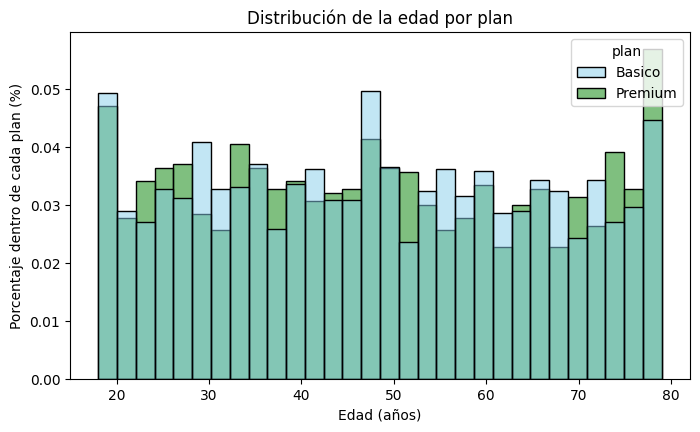

In [41]:
# Histograma para visualizar la edad (age)
plt.figure(figsize=(8, 4.5))
sns.histplot(data=user_profile, x='age', hue='plan', hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], bins=30, multiple='layer',
             stat='probability', common_norm=False)
plt.title('Distribución de la edad por plan')
plt.xlabel('Edad (años)')
plt.ylabel('Porcentaje dentro de cada plan (%)')
plt.show()

💡Insights: 
- Distribución: Casi uniforme y simétrica (asimetría de 0.05), con edades repartidas entre 18 y 79 años y sin una forma de campana.
- Plan: No hay patrón. La edad media es 48.0 en Básico y 48.3 en Premium, con la misma mediana (48)). Por rangos, la proporción de usuarios de 18 a 29, 30 a 44, 45 a 59 y 60 a 79 años es casi igual en ambos planes.

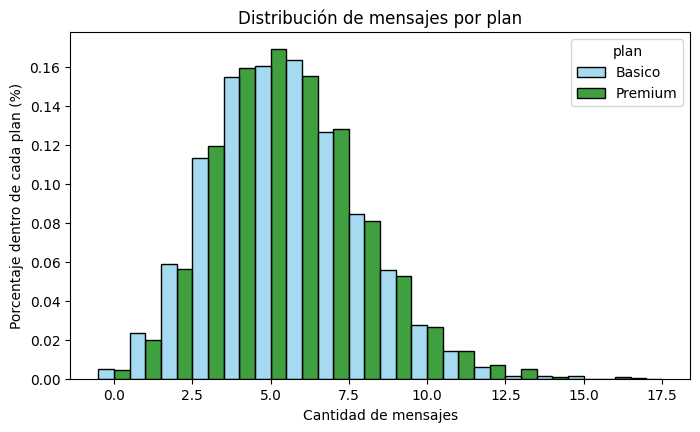

In [42]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8, 4.5))
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], discrete=True, multiple='dodge',
             stat='probability', common_norm=False)
plt.title('Distribución de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Porcentaje dentro de cada plan (%)')
plt.show()

💡Insights: 
- Distribución: Ligeramente sesgada a la derecha (0.46), concentrada entre 3 y 8 mensajes por usuario, con cola hasta 17.
- Plan: No hay patrón. Los usuarios Básico y Premium envían en promedio 5.5 mensajes, con la misma mediana (5) y la misma dispersión (2.4). 

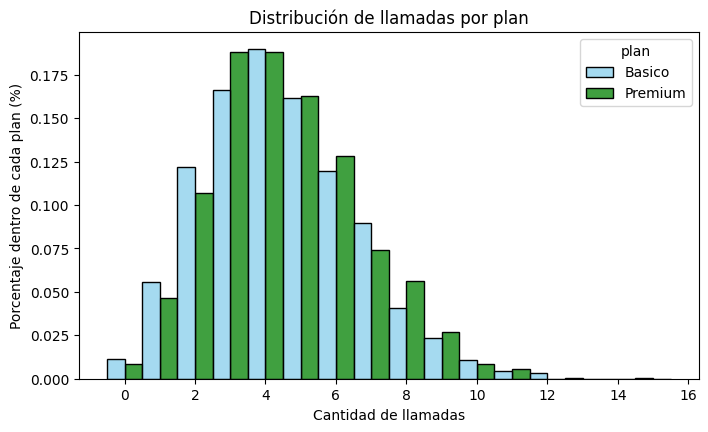

In [43]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 4.5))
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], discrete=True, multiple='dodge',
             stat='probability', common_norm=False)
plt.title('Distribución de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Porcentaje dentro de cada plan (%)')
plt.show()

💡Insights: 
- Distribución: Ligeramente sesgada a la derecha (0.50), concentrada entre 2 y 6 llamadas.
- Plan: Es prácticamente igual. Los usuarios Básico hacen 4.45 llamadas en promedio y los Premium 4.52, con mediana de 4 en ambos. La única diferencia visible es la cola: el máximo es 15 en Básico y 11 en Premium

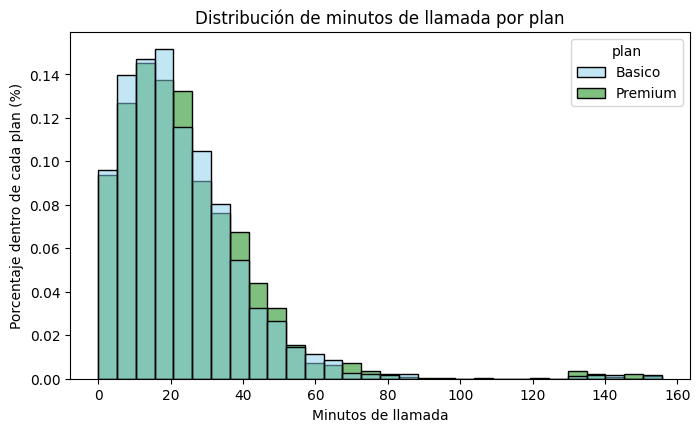

In [44]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 4.5))
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], bins=30, multiple='layer',
             stat='probability', common_norm=False)
plt.title('Distribución de minutos de llamada por plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Porcentaje dentro de cada plan (%)')
plt.show()

💡Insights: 
- Distribución: Claramente sesgada a la derecha (asimetría de 2.5), con la mayor parte de usuarios entre 5 y 40 minutos y una cola larga. El promedio (23.3) supera a la mediana (19.8).
- Plan: Los usuarios Premium hablan en promedio 24.1 minutos y los Básico 22.9 (un 5% más), con percentiles muy parecidos (el percentil 95 es 52.0 contra 52.2). No hay un patrón fuerte.
- Hallazgo clave: Puede haber un sesgo de la cantidad de minutos por llamada superiores a 100 minutos, puede sugerir un tope o un error en el sistema por lo que seria apropiado una revision.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

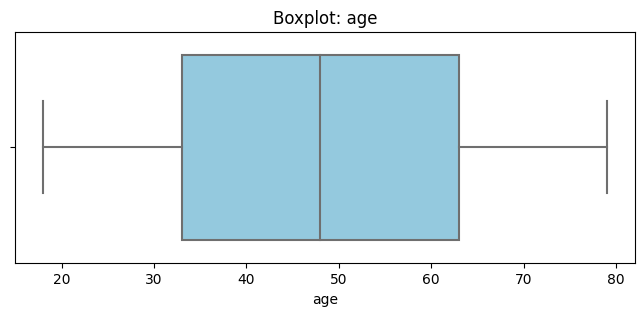

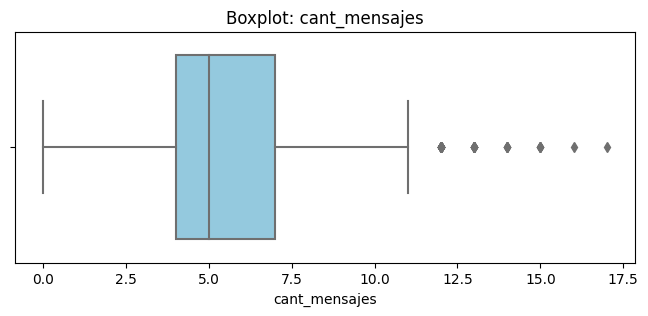

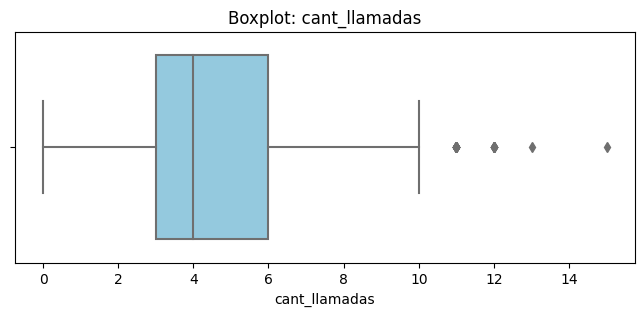

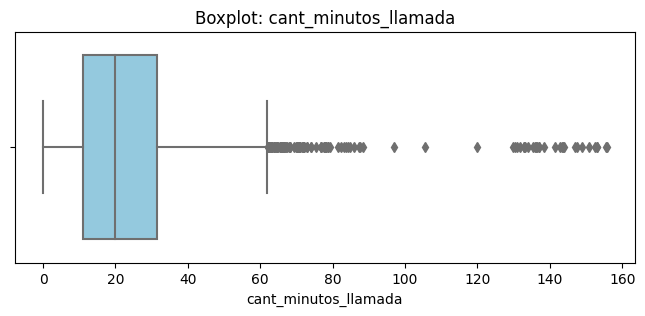

In [45]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: No presenta outliers. Los bigotes llegan a los extremos (18 y 79) y no hay puntos fuera.
- cant_mensajes: Sí presenta outliers, solo del lado derecho. Aparecen puntos desde 12 hasta 17 mensajes.
- cant_llamadas: Sí presenta outliers, solo del lado derecho. Aparecen puntos desde 11 hasta 15 llamadas
- cant_minutos_llamada: Sí presenta outliers, solo del lado derecho, y son los más marcados: una nube de puntos desde unos 62 minutos y otro grupo separado entre 130 y 155.

In [46]:

# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    n_outliers = (user_profile[col] > limite_superior).sum()
    print(f"{col}: Q1={q1}, Q3={q3}, IQR={iqr:.2f}, "
          f"límite superior={limite_superior:.2f}, "
          f"outliers={n_outliers} ({n_outliers / len(user_profile):.2%})")

cant_mensajes: Q1=4.0, Q3=7.0, IQR=3.00, límite superior=11.50, outliers=46 (1.15%)
cant_llamadas: Q1=3.0, Q3=6.0, IQR=3.00, límite superior=10.50, outliers=30 (0.75%)
cant_minutos_llamada: Q1=11.1075, Q3=31.4125, IQR=20.30, límite superior=61.87, outliers=109 (2.73%)


In [47]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
 -- Mantener. El porcentaje es de 1.15%, con un valor maximo de 17, lo cual es posible y no hay una brecha grande por lo que se puede considerar usuarios de consumo alto.
- cant_llamadas: mantener o no outliers, porqué?
  -- Mantener. Es un porcentaje menor, sin brecha considerable respecto a distribucion estandar.
- cant_minutos_llamada: mantener o no outliers, porqué?
  -- Mantener, los usuarios con consumos inferiores a 100 minutos ya que es algo estadisticamente esperable; pero hay varios valores con una duracion exacta de 120 minutos, el mismo valor sospechoso que detectamos en usage, que parece un tope o un error del sistema. En este caso no se eliminan como usuarios, pero la llamada de 120 minutos debe revisarse.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [48]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),    # Bajo uso
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)   # Uso medio
]
categorias = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(condiciones, categorias, default='Alto uso')

In [49]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaT,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaT,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaT,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaT,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaT,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [50]:
# Crear columna grupo_edad
condiciones = [
    user_profile['age'] < 30, 
    user_profile['age'] < 60 
]
categorias = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones, categorias, default='Adulto Mayor')

In [51]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaT,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaT,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaT,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaT,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaT,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

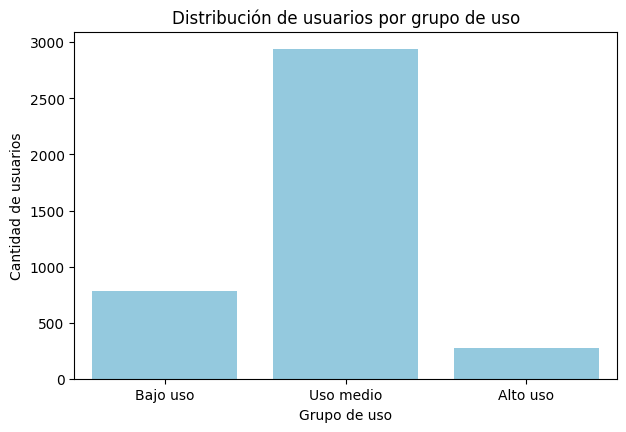

In [52]:
# Visualización de los segmentos por uso
plt.figure(figsize=(7, 4.5))
ax = sns.countplot(data=user_profile, x='grupo_uso',
                   order=['Bajo uso', 'Uso medio', 'Alto uso'],
                   color='skyblue')
plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

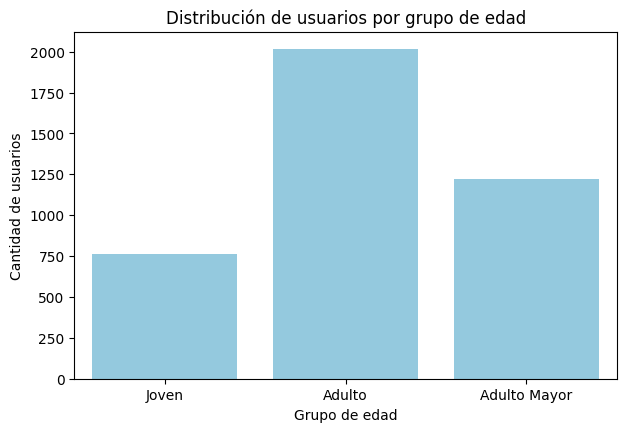

In [53]:
# Visualización de los segmentos por edad
plt.figure(figsize=(7, 4.5))
ax = sns.countplot(data=user_profile, x='grupo_edad',
                   order=['Joven', 'Adulto', 'Adulto Mayor'],
                   color='skyblue')
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

In [54]:
# Cobertura y coherencia de fechas
print("Rango de usage.date:", usage['date'].min(), "→", usage['date'].max())
print(usage['date'].dt.to_period('M').value_counts().sort_index())

uso_fechas = usage.merge(users[['user_id', 'reg_date']], on='user_id', how='left')
antes = uso_fechas['date'] < uso_fechas['reg_date']
print(f"\nUso anterior al registro: {antes.sum()} ({antes.mean():.1%})")
print("Bajas anteriores al registro:", (users['churn_date'] < users['reg_date']).sum())
print("\nBajas por mes:")
print(users['churn_date'].dt.to_period('M').value_counts().sort_index())

Rango de usage.date: 2024-01-01 00:00:00 → 2024-06-30 00:00:00
2024-01    6843
2024-02    6403
2024-03    6837
2024-04    6622
2024-05    6843
2024-06    6402
Freq: M, Name: date, dtype: int64

Uso anterior al registro: 10078 (25.2%)
Bajas anteriores al registro: 0

Bajas por mes:
Series([], Freq: M, Name: churn_date, dtype: int64)


In [55]:
# Valores sospechosos en usage
print("\nLlamadas de 120 min:", (usage['duration'] == 120).sum())
print("Mensajes con length > 160:", (usage['length'] > 160).sum())


Llamadas de 120 min: 30
Mensajes con length > 160: 30


In [56]:
# Churn global y por segmento
user_profile['churn'] = user_profile['churn_date'].notna()
print(f"Churn global: {user_profile['churn'].mean():.2%}\n")
for col in ['grupo_edad', 'grupo_uso', 'plan']:
    print((user_profile.groupby(col)['churn'].mean() * 100).round(1), "\n")

Churn global: 0.00%

grupo_edad
Adulto          0
Adulto Mayor    0
Joven           0
Name: churn, dtype: int64 

grupo_uso
Alto uso     0
Bajo uso     0
Uso medio    0
Name: churn, dtype: int64 

plan
Basico     0
Premium    0
Name: churn, dtype: int64 



In [57]:
# Ingreso mensual base por plan (tarifa del plan; no incluye cargos extra)
precio = plans.set_index('plan_name')['usd_monthly_pay']
user_profile['ingreso_base'] = user_profile['plan'].map(precio)
print("Ingreso base, todos los usuarios:")
print(user_profile.groupby('plan')['ingreso_base'].sum())
print("Total:", user_profile['ingreso_base'].sum())
print("\nIngreso base, solo usuarios activos:")
print(user_profile[~user_profile['churn']].groupby('plan')['ingreso_base'].sum())

Ingreso base, todos los usuarios:
plan
Basico     31140
Premium    35125
Name: ingreso_base, dtype: int64
Total: 66265

Ingreso base, solo usuarios activos:
plan
Basico     31140
Premium    35125
Name: ingreso_base, dtype: int64


In [58]:
# Alto uso por plan y consumo mensual frente a lo incluido en el plan
print(pd.crosstab(user_profile['plan'], user_profile['grupo_uso']))

usage['mes'] = usage['date'].dt.to_period('M')
mensual = (usage.groupby(['user_id', 'mes'])
                .agg(mensajes=('is_text', 'sum'), minutos=('minutos_llamada', 'sum'))
                .reset_index()
                .merge(users[['user_id', 'plan']], on='user_id'))
print("\nMáximo mensual por plan:")
print(mensual.groupby('plan')[['mensajes', 'minutos']].max())
print("\nPromedio mensual por usuario-mes con actividad:")
print(mensual[['mensajes', 'minutos']].mean().round(1))

alto_basico = user_profile[(user_profile['plan'] == 'Basico') &
                           (user_profile['grupo_uso'] == 'Alto uso')]['user_id']
print("\nAlto uso en Básico:", len(alto_basico))
print("...que superó 100 min en algún mes:",
      mensual[mensual['user_id'].isin(alto_basico) & (mensual['minutos'] > 100)]['user_id'].nunique())

grupo_uso  Alto uso  Bajo uso  Uso medio
plan                                    
Basico          185       513       1897
Premium          93       266       1046

Máximo mensual por plan:
         mensajes  minutos
plan                      
Basico          7   131.96
Premium         6   130.54

Promedio mensual por usuario-mes con actividad:
mensajes    1.1
minutos     4.7
dtype: float64

Alto uso en Básico: 185
...que superó 100 min en algún mes: 0


In [59]:
# ¿La ciudad explica el uso?
print("\nUso promedio por ciudad:")
print(user_profile.groupby('city')[cols_uso].mean().round(2))


Uso promedio por ciudad:
          cant_mensajes  cant_llamadas  cant_minutos_llamada
city                                                        
Bogotá             5.62           4.49                 23.14
CDMX               5.59           4.43                 22.65
Cali               5.53           4.49                 23.09
GDL                5.37           4.42                 24.62
MTY                5.41           4.54                 23.74
Medellín           5.44           4.51                 23.84



---
## 🧩Paso 7: 

Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

El análisis comenzó importando las librerias y cargando los tres archivos: plans (2 filas y 8 columnas), users (4000 filas y 8 columnas) y usage (40000 filas y 6 columnas). 
Al revisar su estructura con .shape e .info() se vio que las columnas de fecha estaban como texto y que había valores ausentes en users (city y churn_date) y en usage (date, duration y length). 
Al explorar los valores aparecieron además dos marcadores que no deberían estar en los datos: el valor -999 en age, presente en 55 usuarios (1.4%), que inflaba la desviación estándar a 123 y bajaba el promedio a 33.7 años, y el símbolo ? en city, presente en 96 usuarios, que junto con 469 nulos dejaba 565 usuarios (14.1%) sin ciudad conocida. Al convertir las fechas se encontraron 40 registros (1.0%) con año de registro 2026, imposible porque los datos llegan hasta 2024. 
En usage había 50 fechas ausentes (0.1%) y los nulos de duration (55.2%) y length (44.7%) resultaron ser estructurales, porque una llamada tiene duración y un mensaje tiene longitud, pero 28 filas (0.07%) no respetaban esa regla. 
También se detectaron 30 llamadas de exactamente 120 minutos, que parecen un tope del sistema, y 30 mensajes de más de 160 caracteres, con un máximo de 1490. Por último, el 25.2% de los registros de uso (10078) tiene fecha anterior al registro del usuario, y el uso solo cubre de enero a junio de 2024.

La limpieza consistió en reemplazar los 55 valores -999 por la mediana de las edades válidas (48 años), con lo que la media quedó en 48.1 y la desviación en 17.7; convertir los ? en nulos; marcar como nulas las 40 fechas de 2026; y mantener como nulos los de duration y length, al comprobar que dependen del tipo de comunicación. Con los datos limpios se resumió el uso por usuario, contando mensajes, llamadas y minutos de llamada y combinando esa tabla con users, lo que dio un perfil de 4000 usuarios con un promedio de 5.5 mensajes, 4.5 llamadas y 23.3 minutos. 
Los histogramas mostraron que la edad es casi uniforme entre 18 y 79 años, que mensajes y llamadas tienen una ligera asimetría hacia la derecha y que los minutos están claramente sesgados a la derecha, y en ninguna variable se vieron diferencias importantes entre los planes Básico y Premium.

Con ese perfil se crearon los segmentos. Por edad, los jóvenes (18 a 29 años) son 760 usuarios (19.0%), los adultos (30 a 59) son 2018 (50.5%) y los adultos mayores (60 a 79) son 1222 (30.6%), y los tres grupos se comportan igual, con unos 5.5 mensajes, 4.5 llamadas y entre 23 y 24 minutos en promedio. Por nivel de uso, 779 usuarios son de bajo uso (19.5%, con unos 3 mensajes y 3 llamadas), 2943 de uso medio (73.6%) y 278 de alto uso (6.95%, con 9.6 mensajes, 6 llamadas y 30 minutos). La distribución de estos segmentos es casi idéntica en ambos planes, de modo que quien paga el plan más caro no consume más. El abandono global es de 11.65% y es algo mayor entre los adultos (12.5%) y, sobre todo, entre los usuarios de alto uso (14.0%, frente a 11.4% y 11.5% en los otros niveles).

Los segmentos más valiosos para ConnectaTel son tres. Los clientes Premium representan el 35% de la base pero aportan el 53% del ingreso mensual base (35,125 de 66,265 dólares), por lo que son el segmento más importante por ingresos y, como se explica más abajo, también el más expuesto. Los usuarios de alto uso son los que más consumen y los que más abandonan, y 185 de ellos están en el plan Básico, lo que los hace el mejor público para una oferta de mejora. Los adultos de 30 a 59 años son la mitad de la base y tienen la tasa de abandono más alta, así que cualquier mejora de retención en ese grupo mueve más ingresos que en otros.

Los boxplots confirmaron que la edad no tiene valores extremos, pero sí los hay en las variables de uso, siempre en el lado superior. Con el método IQR, 46 usuarios (1.15%) superan los 11.5 mensajes y 30 (0.75%) superan las 10.5 llamadas, con máximos de 17 y 15, valores plausibles y sin salto respecto al resto, por lo que se mantienen como usuarios muy activos. En minutos, 109 usuarios (2.7%) superan el límite de 61.9, y aunque la mayoría es uso intenso real (entre 62 y 100 minutos), unos 31 superan los 100 y forman un grupo separado, causado por las llamadas de exactamente 120 minutos. Eso implica que los extremos reales son una oportunidad comercial, mientras que los de 120 minutos pueden llevar a sobrestimar la demanda de minutos y deben revisarse antes de fijar precios.

Con base en todo esto, la recomendación principal es revisar el valor percibido de Premium: ningún usuario de ese plan supera 6 mensajes ni 130.5 minutos en un mes, frente a los 500 mensajes y 600 minutos que incluye, y su consumo es igual al de Básico, así que el plan que sostiene más de la mitad del ingreso es vulnerable a bajas de plan si el cliente no percibe qué obtiene por el doble de precio. Conviene confirmar qué otro valor aporta (por ejemplo, 20 GB frente a 5) y comunicarlo, y estudiar un plan intermedio entre 12 y 25 dólares con cuotas cercanas al consumo real, validándolo antes con datos de consumo de GB, que este dataset no incluye. También se recomienda un programa de retención para el segmento de alto uso y una oferta de mejora para los 185 usuarios de alto uso en Básico, en particular para los 9 que ya superaron los 100 minutos incluidos en algún mes, mientras que no se justifica diseñar planes por edad, porque los datos no muestran diferencias de comportamiento entre grupos de edad. Finalmente, hay que corregir la captura de datos en el origen (marcadores -999 y ?, exportación de churn_date, fechas futuras, tope de 120 minutos, nombres de ciudad mezclados y uso anterior al registro) y ampliar el registro de uso al año completo y al consumo de datos. Como advertencias, las bajas ocurren entre junio y diciembre y el uso solo llega a junio, así que la relación entre uso y abandono es indicativa; las diferencias de abandono entre segmentos son pequeñas y no se probaron estadísticamente; y el consumo observado es bajo (en promedio, 1.1 mensajes y 4.7 minutos por usuario en cada mes con actividad), lo que sugiere que el registro de uso podría ser una muestra del consumo real.


### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- `age`: 55 usuarios (1.4%) tenían el valor imposible -999, que inflaba la desviación estándar a 123 y bajaba la media a 33.7 años. Se reemplazó por la mediana (48 años) y la media quedó en 48.1.
- `city`: 565 usuarios (14.1%) tenían ciudad desconocida (469 nulos y 96 con ?). Además se mezclan nombres completos (Bogotá, Cali) y abreviados (CDMX, GDL, MTY).
- `reg_date`: [40] usuarios ([1.0%]) con fecha de registro en 2026, posterior al corte de los datos (2024). Se marcaron como nulos.
- `usage.date`: 50 filas (0.1%) sin fecha.
- `duration` y `length`: nulos estructurales (55.2% y 44.7%), porque una llamada tiene duración y un mensaje tiene longitud. 28 filas (0.07%) no respetan esa regla.
- Valores sospechosos en usage: [30] llamadas de exactamente 120 minutos (posible tope del sistema) y [30] mensajes de más de 160 caracteres, con un máximo de 1490.
- Coherencia de fechas: [25.2%] de los registros de uso tienen fecha anterior al registro del usuario, y el uso cubre solo de [enero a junio] de 2024.

🔍 **Segmentos por Edad**
- `Joven` (18 a 29): [760] usuarios ([19.0%]). Adulto (30 a 59): [2018] ([50.5%]). Adulto Mayor (60 a 79): [1222] ([30.6%]).
- La edad no cambia el comportamiento de uso: los tres grupos envían unos 5.5 mensajes, hacen unas 4.5 llamadas y hablan entre 23 y 24 minutos en promedio.
- Tampoco cambia el plan contratado: la mezcla de edades es casi idéntica en Básico y Premium.

📊 **Segmentos por Nivel de Uso**
- `Bajo uso`: [779] usuarios ([19.5%]), con [3.1] mensajes, [2.8] llamadas y [14.9] minutos.
- `Uso medio`: [2943] usuarios ([73.6%]), con [5.8] mensajes, [4.8] llamadas y [24.9] minutos.
- `Alto uso`: [278] usuarios ([6.95%]), con [9.6] mensajes, [6.0] llamadas y [30.2] minutos.
- El plan no explica el uso: el `alto uso` es [7.1%] en `Básico` y [6.6%] en `Premium`. Quien paga 25 USD consume lo mismo que quien paga 12 USD.
- Abandono: el churn global es de 11.65%. Es mayor en `Adulto` ([12.5%]) y en `Alto uso` ([14.0%], frente a [11.4%] y [11.5%] en los otros niveles). Las diferencias son pequeñas y no se probaron estadísticamente.

- Outliers: 
    El 1.15% de los usuarios supera los 11.5 mensajes y el 0.75% supera las 10.5 llamadas, con máximos plausibles de 17 y 15, así que se mantienen.
    En minutos, el 2.7% supera los 61.9: la mayoría es uso intenso real (62 a 100 minutos), pero [31] usuarios superan los 100 por las llamadas de exactamente 120 minutos, que deben revisarse antes de fijar precios.


➡️ Esto sugiere que ni la edad ni el plan explican cómo usa el servicio un cliente: lo que importa es el nivel de uso y el desajuste entre lo que se paga y lo que se consume. Los segmentos más valiosos son:

 - `Clientes Premium`: el 35% de la base. Ningún usuario Premium supera 6 mensajes ni 130.5 minutos en un mes, frente a 500 mensajes y 600 minutos incluidos, por lo que es el segmento más valioso y también el más expuesto.
- `Alto uso`: los que más consumen y los que más abandonan, y 185 de ellos están en Básico.
- Hay 266 usuarios Premium de bajo uso que son el 18.9% de los Premium. Así que el riesgo no es la baja sino un posible cambio a un plan más barato. Es un riesgo potencial.
- Ninguna variable demográfica disponible explica el uso, Ni la edad, ni el plan, ni la ciudad: los promedios y comprotamiento no varian de ciudad o pais. Por eso la segmentación útil es la de comportamiento (nivel de uso) y la de valor (ingreso por plan), y no la demográfica.

💡 **Recomendaciones**
- Revisar el valor percibido de `Premium` (prioridad alta). Su consumo es igual al de Básico, y es el plan que sostiene más de la mitad del ingreso. Conviene confirmar qué otro valor aporta y comunicarlo.
- Estudiar un plan intermedio entre 12 y 25 usd, con cuotas de minutos y mensajes cercanas al consumo real y los datos como diferenciador. Antes hay que validarlo con consumo de GB, que este dataset no incluye.
- Oferta de mejora para los 185 usuarios de alto uso en Básico, y en especial para los 9 que ya superaron los 100 minutos incluidos en algún mes.
- No diseñar planes por edad: los datos no muestran diferencias de comportamiento entre grupos de edad.
- Corregir la captura de datos en el origen: marcadores -999 y ?, exportación de churn_date, fechas futuras, tope de 120 minutos, nombres de ciudad mezclados y uso anterior al registro. También ampliar el registro de uso al año completo y a consumo de datos.

Advertencias: 
- Las bajas ocurren entre [junio y diciembre] y el uso solo llega hasta [junio], así que la relación entre uso y abandono es indicativa.
- El consumo observado es bajo (en promedio [1.1] mensajes y [4.7] minutos por usuario en cada mes con actividad), lo que sugiere que el registro de uso podría ser una muestra del consumo real.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`